In [2]:
import torch
print(torch.cuda.is_available())

True


In [4]:
import kagglehub

path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
print(path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
/kaggle/input/plantvillage-dataset


In [6]:
import os

root = os.path.join(path, "plantvillage dataset", "color")
classes = sorted(os.listdir(root))
print(len(classes))
for c in classes[:10]:
    print(c, len(os.listdir(os.path.join(root, c))))

38
Apple___Apple_scab 630
Apple___Black_rot 621
Apple___Cedar_apple_rust 275
Apple___healthy 1645
Blueberry___healthy 1502
Cherry_(including_sour)___Powdery_mildew 1052
Cherry_(including_sour)___healthy 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot 513
Corn_(maize)___Common_rust_ 1192
Corn_(maize)___Northern_Leaf_Blight 985


In [8]:
import os, torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

chosen = [
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Apple___healthy",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Cherry_(including_sour)___Powdery_mildew",
    "Cherry_(including_sour)___healthy",
]

# Make a small folder containing only the chosen classes
subset_dir = "/content/data"
os.makedirs(subset_dir, exist_ok=True)
for c in chosen:
    dst = os.path.join(subset_dir, c)
    if not os.path.exists(dst):
        os.symlink(os.path.join(root, c), dst)

# Image preparation (size 224 and normalization are what MobileNet expects)
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    norm,
])
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    norm,
])

train_full = datasets.ImageFolder(subset_dir, transform=train_tf)
val_full = datasets.ImageFolder(subset_dir, transform=val_tf)

# 80/20 split
g = torch.Generator().manual_seed(42)
idx = torch.randperm(len(train_full), generator=g).tolist()
split = int(0.8 * len(idx))
train_ds = Subset(train_full, idx[:split])
val_ds = Subset(val_full, idx[split:])

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, num_workers=2)

print(train_full.classes)
print(len(train_ds), len(val_ds))

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight']
5583 1396


In [10]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained model
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Freeze the pretrained layers (they already know how to see shapes and textures)
for p in model.parameters():
    p.requires_grad = False

# Replace the last layer with one for our 7 classes
model.classifier[1] = nn.Linear(model.last_channel, 7)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

for epoch in range(5):
    # Training
    model.train()
    running_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    # Validation
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            correct += (model(images).argmax(1) == labels).sum().item()

    print(f"Epoch {epoch+1}/5  loss: {running_loss/len(train_loader):.4f}  "
          f"val accuracy: {correct/len(val_ds)*100:.1f}%")

Epoch 1/5  loss: 0.5337  val accuracy: 97.9%
Epoch 2/5  loss: 0.1580  val accuracy: 98.6%
Epoch 3/5  loss: 0.1040  val accuracy: 98.7%
Epoch 4/5  loss: 0.0816  val accuracy: 98.8%
Epoch 5/5  loss: 0.0680  val accuracy: 98.8%


                                          precision    recall  f1-score   support

                      Apple___Apple_scab      0.958     0.935     0.947       123
                       Apple___Black_rot      0.984     0.984     0.984       125
                         Apple___healthy      0.976     0.994     0.985       332
Cherry_(including_sour)___Powdery_mildew      0.995     0.981     0.988       210
       Cherry_(including_sour)___healthy      1.000     1.000     1.000       166
             Corn_(maize)___Common_rust_      1.000     0.996     0.998       257
     Corn_(maize)___Northern_Leaf_Blight      0.995     1.000     0.997       183

                                accuracy                          0.988      1396
                               macro avg      0.987     0.984     0.986      1396
                            weighted avg      0.988     0.988     0.988      1396



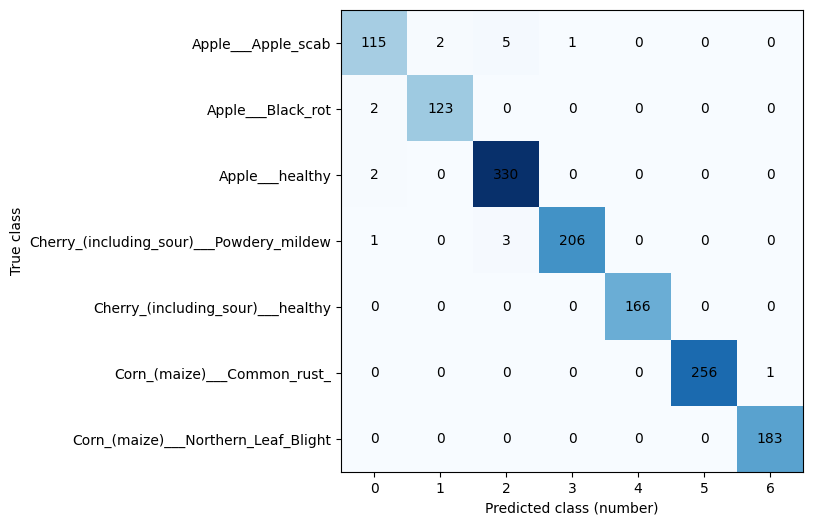

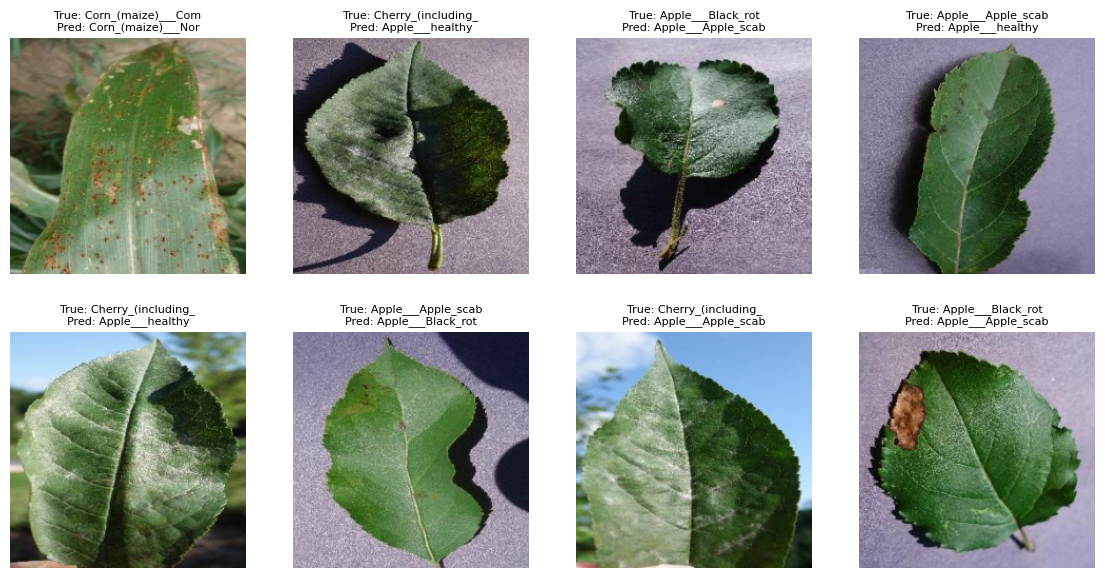

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

class_names = train_full.classes
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        preds = model(images.to(device)).argmax(1)
        all_preds += preds.cpu().tolist()
        all_labels += labels.tolist()

# 1. Per-class report
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

# 2. Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.yticks(range(7), class_names)
plt.xticks(range(7), range(7))
plt.xlabel("Predicted class (number)")
plt.ylabel("True class")
for i in range(7):
    for j in range(7):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.show()

# 3. Show up to 8 wrong predictions
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
wrong = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p != l][:8]
plt.figure(figsize=(14, 7))
for k, i in enumerate(wrong):
    img, _ = val_ds[i]
    img = np.clip(img.permute(1, 2, 0).numpy() * std + mean, 0, 1)
    plt.subplot(2, 4, k + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"True: {class_names[all_labels[i]][:18]}\nPred: {class_names[all_preds[i]][:18]}", fontsize=8)
plt.show()

In [14]:
import json
from google.colab import files

torch.save(model.state_dict(), "plant_model.pth")
with open("class_names.json", "w") as f:
    json.dump(train_full.classes, f)

files.download("plant_model.pth")
files.download("class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>